# Quick start: one simulated image from DIRSIG

From a fresh clone to one simulated 16 × 16 image and its result, then the same simulation with another sensor. Every step is a cell of a few lines; each says what you could change. The words follow the [glossary](../docs/User_glossary.md), which maps them to the names the software prints; the [user manual](../docs/User_manual.md) goes further (sweeps over sensors, space-to-space simulations, reading results, what each message means).

Before the first run: `python scripts/bootstrap.py install` links your DIRSIG installation into the clone. Without DIRSIG, the checks still run and each cell that needs DIRSIG prints why it skips.

Set up: find DIRSIG and open a workspace, the folder where every simulation and its result are kept (change `WORK` to keep them elsewhere).

In [1]:
import os
import sys
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIRSIG = PROJECT / "external" / "dirsig"                    # linked by scripts/bootstrap.py install
if not os.environ.get("DIRSIG_HOME") and (DIRSIG / "bin" / "dirsig5").is_file():
    os.environ["DIRSIG_HOME"] = str(DIRSIG.resolve())
if os.environ.get("DIRSIG_HOME"):
    os.environ["PATH"] = f"{Path(os.environ['DIRSIG_HOME']) / 'bin'}{os.pathsep}" + os.environ.get("PATH", "")
try:
    from manifold.sim import Workspace
except ImportError:                                         # not installed: use the clone's source folders
    sys.path[:0] = [str(PROJECT / "packages" / d / "src") for d in ("core", "sim")]
    from manifold.sim import Workspace

WORK = Path(os.environ.get("QUICKSTART_WORK") or PROJECT / "outputs" / "quickstart")
ws = Workspace.local(work=WORK)
dirsig = next(e for e in ws.list_engines().items if e.engine_id == "dirsig")
HAVE_DIRSIG = dirsig.available
print("DIRSIG ready:", HAVE_DIRSIG, "" if HAVE_DIRSIG else f"({dirsig.reason})")
print("simulations are kept in", WORK.relative_to(PROJECT) if WORK.is_relative_to(PROJECT) else WORK)

DIRSIG ready: True 
simulations are kept in outputs/quickstart


Pick a shipped recipe, the file that describes a simulation by naming a sensor and a scene and giving the camera settings, and make its image 16 × 16 pixels (change the name to any of the recipes listed, or the window size).

In [2]:
print("shipped recipes:", [r.name for r in ws.list_recipes().items])

recipe = ws.get_recipe("auror_ref").document              # the AUROR NIR camera over DIRSIG's Tahoe scene
recipe["settings"][0]["roi"].update(Width=16, Height=16)  # the window; 500 x 500 as shipped

print("sensor  :", recipe["sensor"])
print("scene   :", recipe["scenario"])
print("settings:", recipe["settings"][0])

shipped recipes: ['auror_ref', 'demo_brdf1_passthrough', 'demo_pointcollectors2_passthrough', 'leo_pass_tahoe', 'pointcollectors2_demo', 'sensor_sweep_tahoe', 'synthetic_vis']
sensor  : auror-nir.yaml
scene   : tahoe_static_pose
settings: {'entry_id': 'auror-nir', 'exposure_time': {'value': 0.005, 'provenance': 'specified'}, 'frame_rate': {'value': 1000, 'provenance': 'specified'}, 'gain': {'value': 1, 'provenance': 'specified'}, 'black_level': {'value': 0, 'provenance': 'specified'}, 'roi': {'Width': 16, 'Height': 16, 'OffsetX': None, 'OffsetY': None}}


Check before running, which starts nothing: every file the recipe names is found and unchanged and the settings suit the sensor, and any message it prints is explained by the [glossary](../docs/User_glossary.md) (its words) and the [table of messages](../docs/User_manual.md#7-when-the-sdk-refuses) (what to do) (set the black level above to 1 to see one).

In [3]:
from manifold.core.errors import ProblemError

def check(recipe):
    try:
        result = ws.validate(recipe).runs[0]
    except ProblemError as e:                              # a message about the recipe itself
        print("ready to run: False")
        print(f"  {e.problem['title']}: {e.problem['detail']}")
        return False
    print("ready to run:", result.valid)
    for c in result.checks:
        for e in c.errors:
            print(f"  {c.check}: {e.title}: {e.detail}")
    return result.valid

ok = check(recipe)

ready to run: True


Run the simulation and wait for its result, which says whether every file DIRSIG should write is there (`complete`); a second run of the same recipe returns this result without rendering again (change `timeout` to wait longer for a larger window).

In [4]:
def simulate(recipe):
    if not HAVE_DIRSIG:
        print("SKIPPED: running needs DIRSIG:", dirsig.reason)
        return None
    started = ws.submit_run(recipe)
    result = ws.wait(started.run_id, timeout=600, poll=1.0)
    print("result:", result.state, "| complete?", result.verdict)
    for e in result.errors:
        print("  ", e.title, e.detail)
    return result

first = simulate(recipe)

result: rendered | complete? complete


Look at the image: save it with its header and read it with `spectral`, installed with the SDK (change `band` for a sensor with several bands); the values are electrons per square metre of focal plane.

lines, samples, bands: (16, 16, 1) | mean: 1440487739228160.0


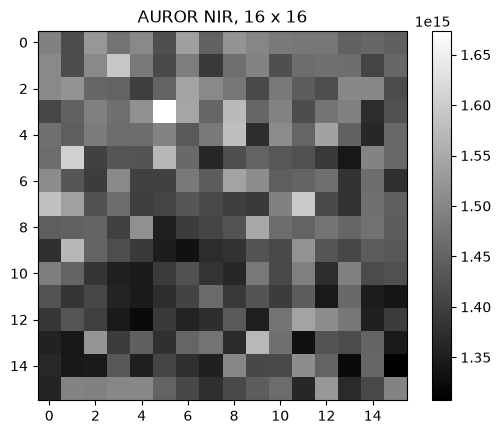

In [5]:
import matplotlib.pyplot as plt
import spectral

def image_of(result, folder):
    folder.mkdir(parents=True, exist_ok=True)
    names = {a.name for a in result.artifacts}
    image = next(a.name for a in result.artifacts if a.role == "product" and a.name.endswith(".img"))
    header = next(h for h in (image + ".hdr", image[:-4] + ".hdr") if h in names)
    for name in (image, header):
        ws.save_artifact(result.run_id, name, folder)
    return spectral.envi.open(str(folder / header), str(folder / image)).load()

band = 0
if first is not None and first.state == "rendered":
    cube = image_of(first, WORK / "files" / "auror-nir")
    print("lines, samples, bands:", cube.shape, "| mean:", float(cube.mean()))
    plt.imshow(cube[:, :, band], cmap="gray")
    plt.title("AUROR NIR, 16 x 16")
    plt.colorbar()
    plt.show()
else:
    print("SKIPPED: no image to show")

Change one thing, the sensor: a different camera from the shipped list, which takes three edits of the recipe rather than one (the sensor's name, the name its settings are filed under, and removing a DIRSIG channel option this camera's measured curves refuse); check it again (change `NEW_SENSOR` to `deepscan_850_306_nir_1280.yaml`, whose settings name is `deepscan-850-306-nir-1280`).

In [6]:
import copy

NEW_SENSOR, NEW_NAME = "synthetic_600_200_vis_1920.yaml", "synthetic-600-200-vis-1920"
print("sensors:", [s.name for s in ws.list_sensors().items])

second_recipe = copy.deepcopy(recipe)
second_recipe["meta"]["name"] = "quickstart-vis"
second_recipe["sensor"] = NEW_SENSOR                     # edit 1: the sensor
second_recipe["settings"][0]["entry_id"] = NEW_NAME      # edit 2: the name its settings are filed under
second_recipe.pop("engine_overrides")                   # edit 3: DIRSIG's own channel shape, which suits only auror-nir
ok = check(second_recipe)

sensors: ['auror-nir.yaml', 'deepscan_850_306_nir_1280.yaml', 'synthetic_600_200_vis_1920.yaml']


ready to run: True


Run it and show the two images side by side, the same scene in another band (change `cmap` for another colour map).

result: rendered | complete? complete


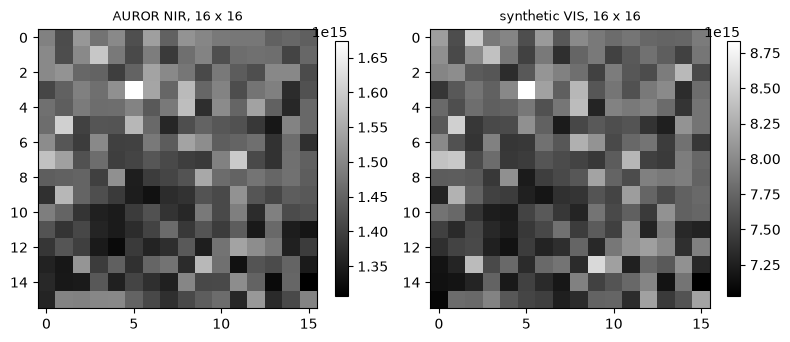

In [7]:
second = simulate(second_recipe)
if second is not None and second.state == "rendered" and first is not None and first.state == "rendered":
    other = image_of(second, WORK / "files" / "vis")
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
    for ax, im, title in zip(axes, (cube, other), ("AUROR NIR", "synthetic VIS")):
        h = ax.imshow(im[:, :, 0], cmap="gray")
        ax.set_title(f"{title}, 16 x 16", fontsize=9)
        fig.colorbar(h, ax=ax, shrink=0.8)
    plt.tight_layout()
    plt.show()
else:
    print("SKIPPED: no second image to show")